# N3 — Dataset Builder

**Purpose:** Build and cache the windowed ECG training dataset from VitalDB.

**What this notebook covers:**
1. Inspect label mapping logic (`assign_label`, `get_window_label`)
2. Dry-run on 5 cases to verify window extraction and labelling
3. Full build: all 482 cases → `windows_train.npz`, `windows_val.npz`, `windows_test.npz`
4. Post-build analysis: class distribution, window counts per split

**Linked module:** `Modules/dataset_builder.py`

> **Note:** The full build downloads ~482 cases from VitalDB. This takes 20-60 minutes
> depending on your internet connection. Run the dry-run cells first to confirm everything works.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'Modules'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vitaldb

import config
from dataset_builder import (
    VitalDBDatasetBuilder, ECGWindowDataset,
    assign_label, get_window_label,
    save_array_if_not_exists, save_dataframe_if_not_exists,
)

print('Imports OK')
print(f'Annotation dir: {config.ANNOTATION_DIR}')
print(f'Output dir:     {config.OUTPUT_DATA_DIR}')


Imports OK
Annotation dir: D:\Codes\Projects\Portable_ECG_Detection_Solution\Dataset\ecg_1_lead_dataset\Annotation_Files
Output dir:     D:\Codes\Projects\Portable_ECG_Detection_Solution\Dataset\Output_Data


In [2]:
# ---- Verify label assignment logic ----
test_cases = [
    # Full names
    ('Normal Sinus Rhythm',                  False, 0),
    ('Atrial Fibrillation',                  False, 1),
    ('Supraventricular Tachyarrhythmia',     False, 2),
    ('Patterned Atrial Ectopy',              False, 2),
    ('Ventricular Tachyarrhythmia',          False, 3),
    ('Patterned Ventricular Ectopy',         False, 3),
    ('Noise',                                False, 4),
    # VitalDB abbreviations from Annotation_Files CSVs
    ('N',                                    False, 0),
    ('AFIB/AFL',                             False, 1),
    ('SVTA',                                 False, 2),
    ('WAP/MAT',                              False, 2),
    ('SND',                                  False, 2),
    ('AVB',                                  False, 2),
    ('VT',                                   False, 3),
    ('Unclassifiable',                       False, 4),
    # bad_signal_quality overrides to Noise (class 4)
    ('Normal Sinus Rhythm',                  True,  4),
    ('N',                                    True,  4),
    ('Atrial Fibrillation',                  True,  4),
    ('AFIB/AFL',                             True,  4),
]

print('assign_label() unit tests:')
all_pass = True
for rhythm, bsq, expected in test_cases:
    result = assign_label(rhythm, bsq)
    status = 'PASS' if result == expected else 'FAIL'
    if status == 'FAIL': all_pass = False
    print(f'  [{status}] rhythm={rhythm!r:45s} bsq={str(bsq):5s} -> got {result}, expected {expected}')

print('\nAll passed!' if all_pass else '\nSome tests FAILED!')


assign_label() unit tests:
  [PASS] rhythm='Normal Sinus Rhythm'                         bsq=False -> got 0, expected 0
  [PASS] rhythm='Atrial Fibrillation'                         bsq=False -> got 1, expected 1
  [PASS] rhythm='Supraventricular Tachyarrhythmia'            bsq=False -> got 2, expected 2
  [PASS] rhythm='Patterned Atrial Ectopy'                     bsq=False -> got 2, expected 2
  [PASS] rhythm='Ventricular Tachyarrhythmia'                 bsq=False -> got 3, expected 3
  [PASS] rhythm='Patterned Ventricular Ectopy'                bsq=False -> got 3, expected 3
  [PASS] rhythm='Noise'                                       bsq=False -> got 4, expected 4
  [PASS] rhythm='N'                                           bsq=False -> got 0, expected 0
  [PASS] rhythm='AFIB/AFL'                                    bsq=False -> got 1, expected 1
  [PASS] rhythm='SVTA'                                        bsq=False -> got 2, expected 2
  [PASS] rhythm='WAP/MAT'                  

In [3]:
# ---- Dry-run: process 3 cases manually ----
builder = VitalDBDatasetBuilder()
meta = pd.read_csv(config.METADATA_CSV)

# Pick 3 representative case_ids
DRY_RUN_IDS = [337, 1023, 103, 244]

for cid in DRY_RUN_IDS:
    row = meta[meta['case_id'] == cid].iloc[0]
    t_start = float(row['analysis_start_time_sec'])
    t_end   = float(row['analysis_end_time_sec'])
    print(f'\n--- Case {cid} | Rhythms: {row["rhythm_classes"]} ---')
    windows, labels = builder._process_case(cid, t_start, t_end)
    print(f'  Windows: {len(windows)}, Labels: {labels.tolist()[:20]}...')
    if len(labels) > 0:
        unique, counts = np.unique(labels, return_counts=True)
        dist = {config.CLASS_NAMES[u]: int(c) for u, c in zip(unique, counts)}
        print(f'  Class dist: {dist}')

2026-10-21 19:45:46,513 INFO Loaded metadata: 482 cases



--- Case 337 | Rhythms: N, SVTA, WAP/MAT ---
  Windows: 348, Labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]...
  Class dist: {'Normal Sinus Rhythm': 221, 'Supraventricular Arrhythmia': 109, 'Noise / Artifact': 18}

--- Case 1023 | Rhythms: AFIB/AFL, Noise ---
  Windows: 647, Labels: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]...
  Class dist: {'Atrial Fibrillation': 628, 'Noise / Artifact': 19}

--- Case 103 | Rhythms: N, Noise, Patterned Atrial Ectopy, VT ---
  Windows: 593, Labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]...
  Class dist: {'Normal Sinus Rhythm': 413, 'Supraventricular Arrhythmia': 11, 'Ventricular Arrhythmia': 1, 'Noise / Artifact': 168}

--- Case 244 | Rhythms: N, Noise, Patterned Atrial Ectopy, Patterned Ventricular Ectopy ---
  Windows: 591, Labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]...
  Class dist: {'Normal Sinus Rhythm': 518, 'Supraventricular Arrhythmia': 14, 'Ventricular Arr

In [4]:
# ---- Preview the patient-wise split ----
splits = builder._split_case_ids()
for split_name, ids in splits.items():
    print(f'{split_name:6s}: {len(ids)} cases')

# Verify no overlap between splits
train_set = set(splits['train'])
val_set   = set(splits['val'])
test_set  = set(splits['test'])
print(f'\nTrain∩Val overlap : {len(train_set & val_set)}')   # must be 0
print(f'Train∩Test overlap: {len(train_set & test_set)}')   # must be 0
print(f'Val∩Test overlap  : {len(val_set & test_set)}')     # must be 0

train : 385 cases
val   : 48 cases
test  : 49 cases

Train∩Val overlap : 0
Train∩Test overlap: 0
Val∩Test overlap  : 0


In [5]:
# ---- FULL BUILD (run when ready — takes 20-60 minutes) ----
# Uses Path.exists() check to skip existing splits and avoid resaving / re-downloading
# NOTE: Set force_rebuild=True if you need to re-extract windows to include newly mapped 'N' and 'AFIB/AFL' labels
FORCE_REBUILD = True

splits = ('train', 'val', 'test')
split_status = {}
for s in splits:
    p = config.OUTPUT_DATA_DIR / f'windows_{s}.npz'
    exists = p.exists()
    split_status[s] = exists
    status_str = 'EXISTS (will not resave)' if exists else 'MISSING (will download & build)'
    print(f'  {s:5s}: {status_str} -> {p}')

all_exist = all(split_status.values())
print(f'\nAll splits cached: {all_exist}')

if FORCE_REBUILD or not all_exist:
    print(f'Starting build (force_rebuild={FORCE_REBUILD})...')
    builder.build_and_cache(force_rebuild=FORCE_REBUILD)
else:
    print('Skipping build: all split files already exist. Set FORCE_REBUILD=True to rebuild.')


2026-10-21 19:46:02,369 INFO Processing split='train' (385 cases)...


  train: MISSING (will download & build) -> D:\Codes\Projects\Portable_ECG_Detection_Solution\Dataset\Output_Data\windows_train.npz
  val  : MISSING (will download & build) -> D:\Codes\Projects\Portable_ECG_Detection_Solution\Dataset\Output_Data\windows_val.npz
  test : MISSING (will download & build) -> D:\Codes\Projects\Portable_ECG_Detection_Solution\Dataset\Output_Data\windows_test.npz

All splits cached: False
Starting build (force_rebuild=True)...


2026-10-21 19:46:43,558 INFO   [train] 10/385 cases done
2026-10-21 19:47:51,690 INFO   [train] 20/385 cases done
2026-10-21 19:48:55,818 INFO   [train] 30/385 cases done
2026-10-21 19:50:02,367 INFO   [train] 40/385 cases done
2026-10-21 19:50:56,539 INFO   [train] 50/385 cases done
2026-10-21 19:51:49,049 INFO   [train] 60/385 cases done
2026-10-21 19:52:38,761 INFO   [train] 70/385 cases done
2026-10-21 19:53:37,472 INFO   [train] 80/385 cases done
2026-10-21 19:54:39,593 INFO   [train] 90/385 cases done
2026-10-21 19:55:33,383 INFO   [train] 100/385 cases done
2026-10-21 19:56:33,388 INFO   [train] 110/385 cases done
2026-10-21 19:57:45,134 INFO   [train] 120/385 cases done
2026-10-21 19:58:36,642 INFO   [train] 130/385 cases done
2026-10-21 19:59:39,866 INFO   [train] 140/385 cases done
2026-10-21 20:00:46,601 INFO   [train] 150/385 cases done
2026-10-21 20:01:55,857 INFO   [train] 160/385 cases done
2026-10-21 20:03:24,075 INFO   [train] 170/385 cases done
2026-10-21 20:04:16,089

train: 211431 windows | {'Normal Sinus Rhythm': 119211, 'Atrial Fibrillation': 47588, 'Supraventricular Arrhythmia': 21113, 'Ventricular Arrhythmia': 7315, 'Noise / Artifact': 16204}
val: 25135 windows | {'Normal Sinus Rhythm': 17683, 'Atrial Fibrillation': 2109, 'Supraventricular Arrhythmia': 2738, 'Ventricular Arrhythmia': 1426, 'Noise / Artifact': 1179}
test: 27833 windows | {'Normal Sinus Rhythm': 16620, 'Atrial Fibrillation': 6494, 'Supraventricular Arrhythmia': 2545, 'Ventricular Arrhythmia': 620, 'Noise / Artifact': 1554}


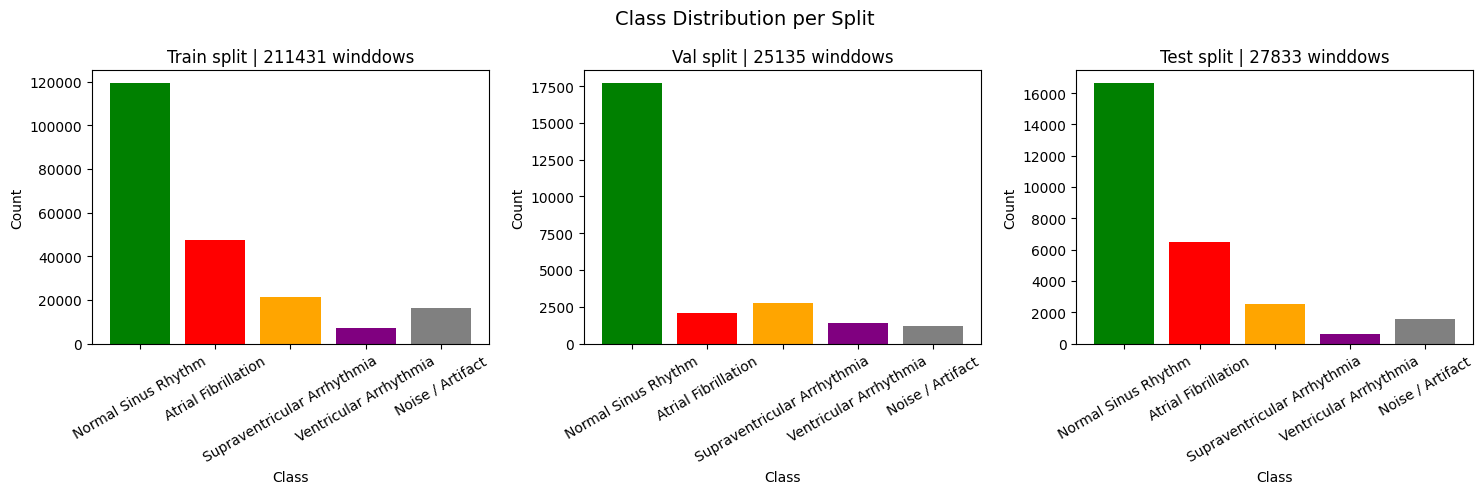

In [6]:
# ---- Post-build: class distribution analysis ----
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, split in zip(axes, ['train', 'val', 'test']):
    npz_path = config.OUTPUT_DATA_DIR / f'windows_{split}.npz'
    if not npz_path.exists():
        ax.set_title(f'{split} (not built yet)')
        continue
    
    data = np.load(npz_path)
    y = data['y']
    unique, counts = np.unique(y, return_counts=True)
    labels = [config.CLASS_NAMES.get(int(u), f'class_{u}') for u in unique]
    
    ax.bar(labels, counts, color=['green', 'red', 'orange', 'purple', 'gray'][:len(labels)])
    ax.set_title(f'{split.capitalize()} split | {len(y)} winddows')
    ax.set_xlabel('Class')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=30)
    
    print(f'{split}: {len(y)} windows | {dict(zip(labels, counts.tolist()))}')

plt.suptitle('Class Distribution per Split', fontsize=14)
plt.tight_layout()
plt.show()